# Vertex efficiency in all ΔR bins: LL, LR, RR, and total


Each map shows efficiency in generated pT–vxy bins for one generated ΔR range.
- LL: electron L, positron L, with a matched reconstructed vertex.
- LR: **electron L, positron R only**; the reverse combination is excluded.
- RR: electron R, positron R, with a matched reconstructed vertex.
- Total: `(N_LL + N_LR + N_RR) / N_den`. This total includes exactly these three mutually exclusive selections.

All categories use the same signal points, cut, and denominator. Counts are summed before division. This reproduces the current unit-weight fills in `drEff.py`; uncertainty intervals assume an unweighted subset of denominator events. Empty denominator bins remain blank.



In [1]:
from pathlib import Path

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
TOOLS_DIR = LPC_REPO / 'python_analysis/analysisTools'

%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

## Load the output and select samples
Change `samples` here once to apply the same selection to all 16 plots. Here `cut0` is the stored cut category; the ΔR split is selected independently from the histogram axis.


In [2]:
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/drEff.coffea'
sig_histo = util.load(str(f_sig))[0]

samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    
         0.2: [100],
    }
}


cut = 'cut0'
year = 2022

categories = ('LL', 'LR', 'RR')
required_histograms = ['genvtx_pt_vxy_dr_den'] + [
    f'genvtx_pt_vxy_dr_{category}' for category in categories
]

si = utils.get_signal_point_dict(sig_histo)
selected_points = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            selected = si[
                np.isclose(si.m1, m1, rtol=1e-8, atol=1e-8)
                & np.isclose(si.delta, delta, rtol=1e-8, atol=1e-8)
                & (si.ctau == ctau)
            ]
            if len(selected) != 1:
                raise ValueError(f'Expected one sample for {(m1, delta, ctau)}; found {len(selected)}.')
            sample_name = selected['name'].iloc[0]
            if sample_name in [point[3] for point in selected_points]:
                raise ValueError(f'Duplicate sample selection: {sample_name}')
            selected_points.append((m1, delta, ctau, sample_name))

if not selected_points:
    raise ValueError('Choose at least one signal point.')

# Check axis names, order, and edges across every histogram and sample.
reference_edges = None
for m1, delta, ctau, sample_name in selected_points:
    for suffix in ('den',) + categories:
        h = sig_histo[f'genvtx_pt_vxy_dr_{suffix}'][{'samp': sample_name, 'cut': cut}]
        expected_names = (f'pt_{suffix}', f'vxy_{suffix}', f'dr_{suffix}')
        if tuple(axis.name for axis in h.axes) != expected_names:
            raise ValueError(f'Unexpected axes for {suffix}: {h.axes}')
        current_edges = tuple(np.asarray(axis.edges).copy() for axis in h.axes)
        if reference_edges is None:
            reference_edges = current_edges
        else:
            for expected, actual in zip(reference_edges, current_edges):
                np.testing.assert_array_equal(expected, actual)

pt_edges, vxy_edges, dr_edges = reference_edges
if len(dr_edges) != 5:
    raise ValueError('This notebook expects four ΔR bins, as in drEff.py.')
print('Selected samples:', [point[3] for point in selected_points])
print('ΔR edges:', dr_edges)


Selected samples: ['sig_2022_Mchi-11p0_dMchi-2p0_ctau-100', 'sig_2022_Mchi-22p0_dMchi-4p0_ctau-100', 'sig_2022_Mchi-33p0_dMchi-6p0_ctau-100', 'sig_2022_Mchi-44p0_dMchi-8p0_ctau-100', 'sig_2022_Mchi-55p0_dMchi-10p0_ctau-100', 'sig_2022_Mchi-63p0_dMchi-6p0_ctau-100', 'sig_2022_Mchi-66p0_dMchi-12p0_ctau-100', 'sig_2022_Mchi-73p5_dMchi-7p0_ctau-100', 'sig_2022_Mchi-77p0_dMchi-14p0_ctau-100', 'sig_2022_Mchi-84p0_dMchi-8p0_ctau-100', 'sig_2022_Mchi-88p0_dMchi-16p0_ctau-100', 'sig_2022_Mchi-94p5_dMchi-9p0_ctau-100', 'sig_2022_Mchi-99p0_dMchi-18p0_ctau-100', 'sig_2022_Mchi-110p0_dMchi-20p0_ctau-100']
ΔR edges: [0.   0.01 0.1  1.   5.  ]


## Collect counts using the plotTools function
The function returns 2D counts after selecting a ΔR bin. Its intermediate count figures are closed; the efficiency figures are displayed below. No rebinning is applied, and underflow/overflow bins are excluded from the maps.


In [3]:
def collect_counts(suffix, dr_bin):
    variable = f'genvtx_pt_vxy_dr_{suffix}'
    summed = None
    for m1, delta, ctau, sample_name in selected_points:
        fig, ax = plt.subplots(figsize=(7, 7))
        plot_dict = {'variable': variable, 'cut': cut, 'year': year}
        style_dict = {
            'fig': fig, 'ax': ax,
            'xrebin': None, 'yrebin': None,
            'xlim': None, 'ylim': None,
            'doLogx': False, 'doLogy': False, 'doLogz': False,
            'xlabel': 'Gen vertex pT [GeV]',
            'ylabel': 'Gen vertex vxy [cm]',
            'zlabel': 'Entries', 'flow': None, 'doSave': False,
        }
        try:
            counts, returned_pt, returned_vxy = ptools.plot_signal_2D_dr(
                sig_histo, m1, delta, ctau, plot_dict, style_dict,
                dr_bin=dr_bin,
            )
            counts = np.asarray(counts, dtype=float)
        finally:
            plt.close(fig)
        np.testing.assert_array_equal(pt_edges, returned_pt)
        np.testing.assert_array_equal(vxy_edges, returned_vxy)
        if counts.shape != (len(pt_edges) - 1, len(vxy_edges) - 1):
            raise ValueError('Unexpected count-array shape.')
        summed = counts.copy() if summed is None else summed + counts
    return summed


def efficiency_and_uncertainty(numerator, denominator):
    if not np.all(np.isfinite(numerator)) or not np.all(np.isfinite(denominator)):
        raise ValueError('Counts contain non-finite values.')
    if np.any(numerator < 0) or np.any(denominator < 0):
        raise ValueError('This efficiency calculation requires nonnegative counts.')
    if np.any(numerator > denominator):
        raise ValueError('Numerator exceeds denominator. Check the selections.')
    if not np.allclose(numerator, np.round(numerator)) or not np.allclose(denominator, np.round(denominator)):
        raise ValueError('Binomial uncertainties here require unit-weight event counts.')
    valid = denominator > 0
    efficiency = np.divide(
        numerator, denominator,
        out=np.full_like(numerator, np.nan, dtype=float), where=valid,
    )
    uncertainty = np.full((2,) + numerator.shape, np.nan)
    if np.any(valid):
        uncertainty[:, valid] = hist.intervals.ratio_uncertainty(
            numerator[valid], denominator[valid], 'efficiency'
        )
    return efficiency, uncertainty


results = {}
for dr_bin in range(len(dr_edges) - 1):
    denominator = collect_counts('den', dr_bin)
    entry = {
        'denominator': denominator,
        'dr_range': (dr_edges[dr_bin], dr_edges[dr_bin + 1]),
    }
    for category in categories:
        numerator = collect_counts(category, dr_bin)
        efficiency, uncertainty = efficiency_and_uncertainty(numerator, denominator)
        entry[category] = {
            'numerator': numerator,
            'efficiency': efficiency,
            'uncertainty': uncertainty,
        }
    total_numerator = sum(entry[category]['numerator'] for category in categories)
    total_efficiency, total_uncertainty = efficiency_and_uncertainty(total_numerator, denominator)
    entry['Total'] = {
        'numerator': total_numerator,
        'efficiency': total_efficiency,
        'uncertainty': total_uncertainty,
    }
    np.testing.assert_allclose(
        total_efficiency,
        sum(entry[category]['efficiency'] for category in categories),
        equal_nan=True,
    )
    results[dr_bin] = entry
    low, high = entry['dr_range']
    print(f'Calculated LL, LR, RR, and total for {low:g} ≤ ΔR < {high:g}')


Calculated LL, LR, RR, and total for 0 ≤ ΔR < 0.01
Calculated LL, LR, RR, and total for 0.01 ≤ ΔR < 0.1
Calculated LL, LR, RR, and total for 0.1 ≤ ΔR < 1
Calculated LL, LR, RR, and total for 1 ≤ ΔR < 5


## Plot helper
The same square-bin style and percentages are used throughout. Colour is efficiency from 0 to 1; blank squares have zero denominator entries. Axis labels give finite bin ranges, not open-ended ranges.


In [4]:
def plot_efficiency_category(category):
    fig, axes = plt.subplots(2, 2, figsize=(15, 13), layout='constrained')
    for ax, dr_bin in zip(axes.flat, results):
        efficiency = results[dr_bin][category]['efficiency'].T
        n_vxy, n_pt = efficiency.shape
        pt_centers = np.arange(n_pt) + 0.5
        vxy_centers = np.arange(n_vxy) + 0.5
        mesh = ax.pcolormesh(
            np.arange(n_pt + 1), np.arange(n_vxy + 1),
            np.ma.masked_invalid(efficiency),
            cmap='viridis', shading='flat', vmin=0, vmax=1,
        )
        ax.set_aspect('equal')
        for iy, y in enumerate(vxy_centers):
            for ix, x in enumerate(pt_centers):
                value = efficiency[iy, ix]
                if np.isfinite(value):
                    ax.text(
                        x, y, f'{100 * value:.2f}%',
                        ha='center', va='center', fontsize=10,
                        color='white' if value < 0.5 else 'black',
                    )
        ax.set_xticks(pt_centers)
        ax.set_xticklabels([f'{a:g}–{b:g}' for a, b in zip(pt_edges[:-1], pt_edges[1:])])
        ax.set_yticks(vxy_centers)
        ax.set_yticklabels([f'{a:g}–{b:g}' for a, b in zip(vxy_edges[:-1], vxy_edges[1:])])
        ax.set_xlabel(r'Gen $p_T(e^+e^-)$ bin [GeV]')
        ax.set_ylabel(r'Gen $L_{xy}(e^+e^-)$ bin [cm]')
        low, high = results[dr_bin]['dr_range']
        ax.set_title(f'{category} efficiency: {low:g} ≤ Gen ΔR < {high:g}')
    title = 'Total = LL + LR + RR (reverse RL excluded)' if category == 'Total' else f'{category} vertex reconstruction efficiency'
    fig.suptitle(title)
    fig.colorbar(mesh, ax=axes.ravel().tolist(), label=f'{category} efficiency', shrink=0.8)
    plt.show()


## LL efficiency — all four ΔR bins


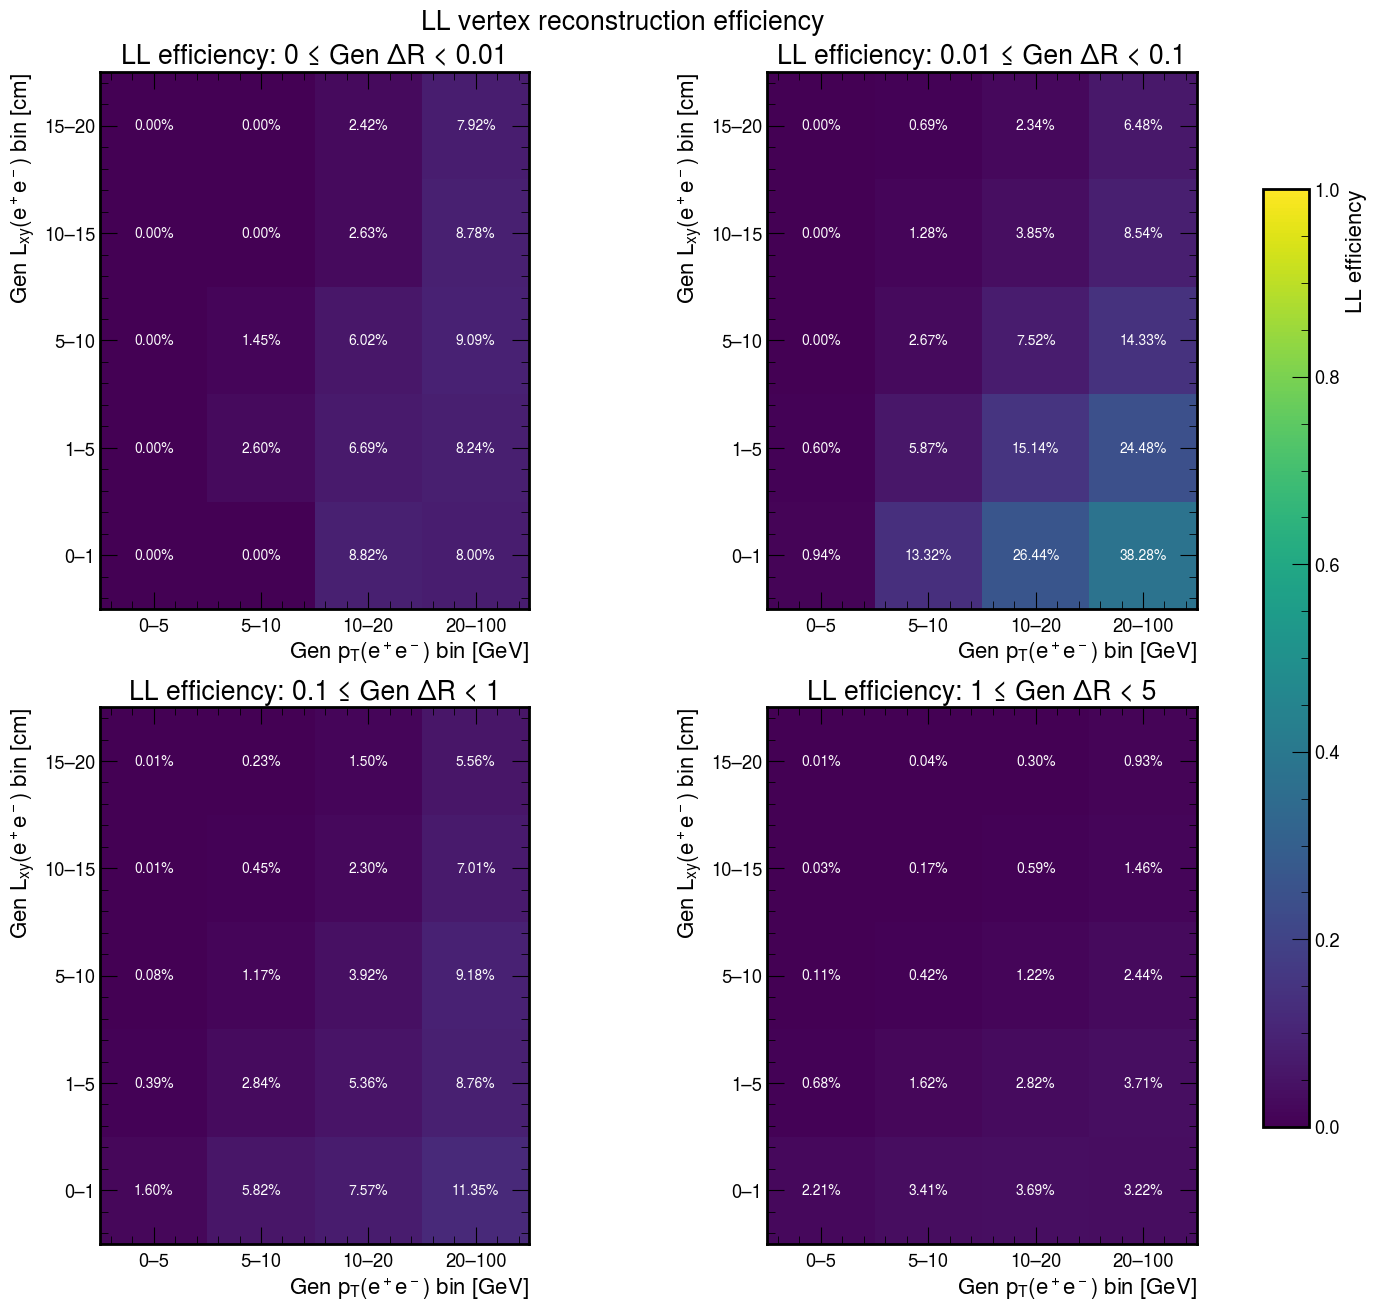

In [5]:
plot_efficiency_category('LL')


## LR efficiency — all four ΔR bins


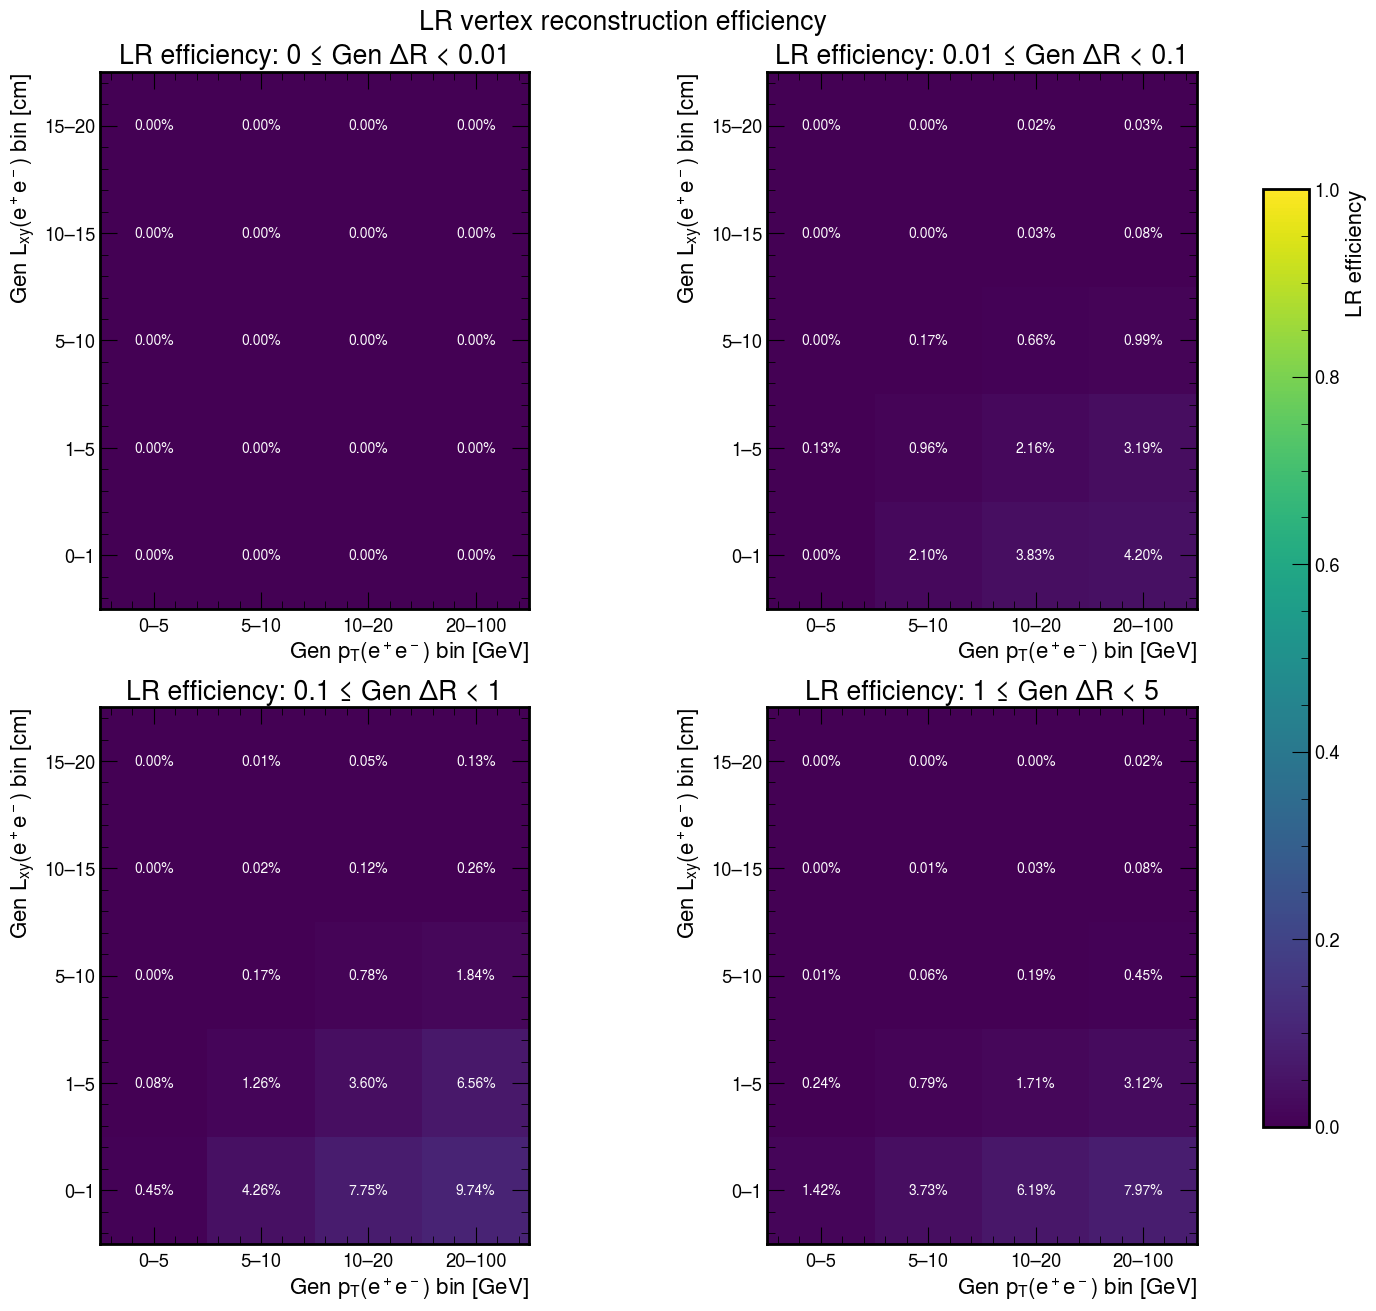

In [6]:
plot_efficiency_category('LR')


## RR efficiency — all four ΔR bins


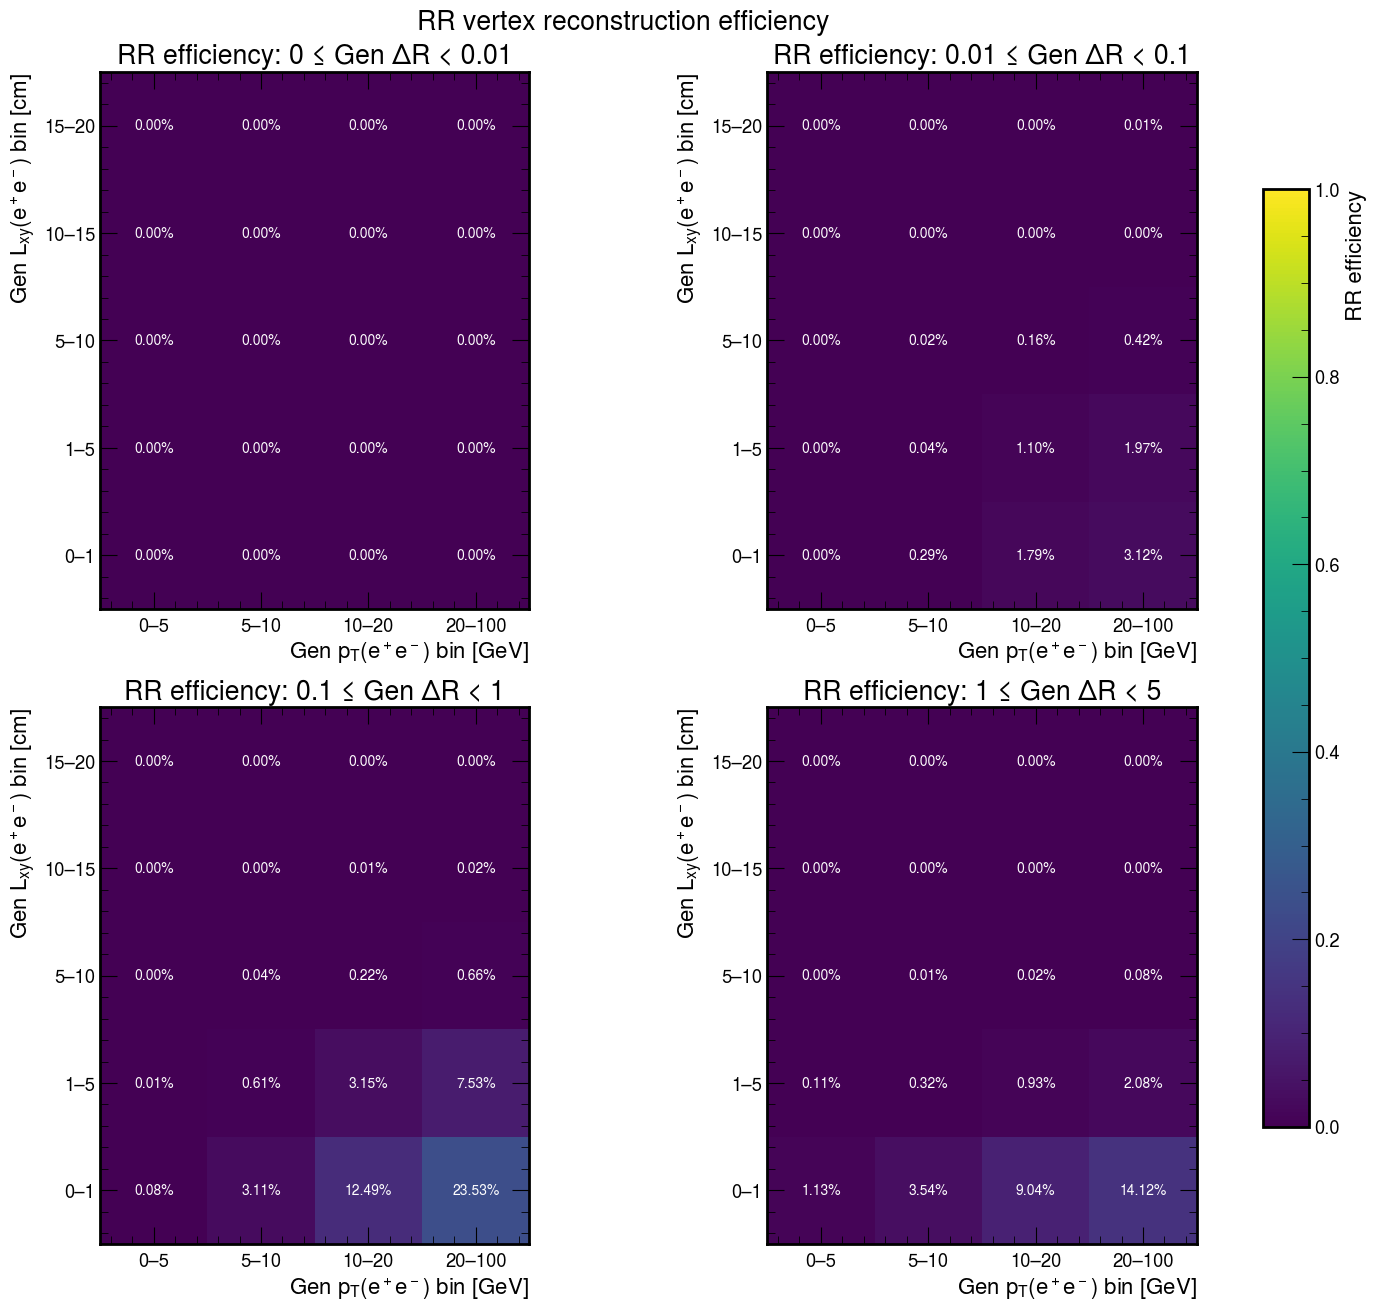

In [7]:
plot_efficiency_category('RR')


## Total efficiency — all four ΔR bins
Total uses the summed LL, LR, and RR numerator counts and the common denominator. Its uncertainty is calculated from those counts, not by adding the three uncertainty arrays. Electron R/positron L is deliberately excluded.


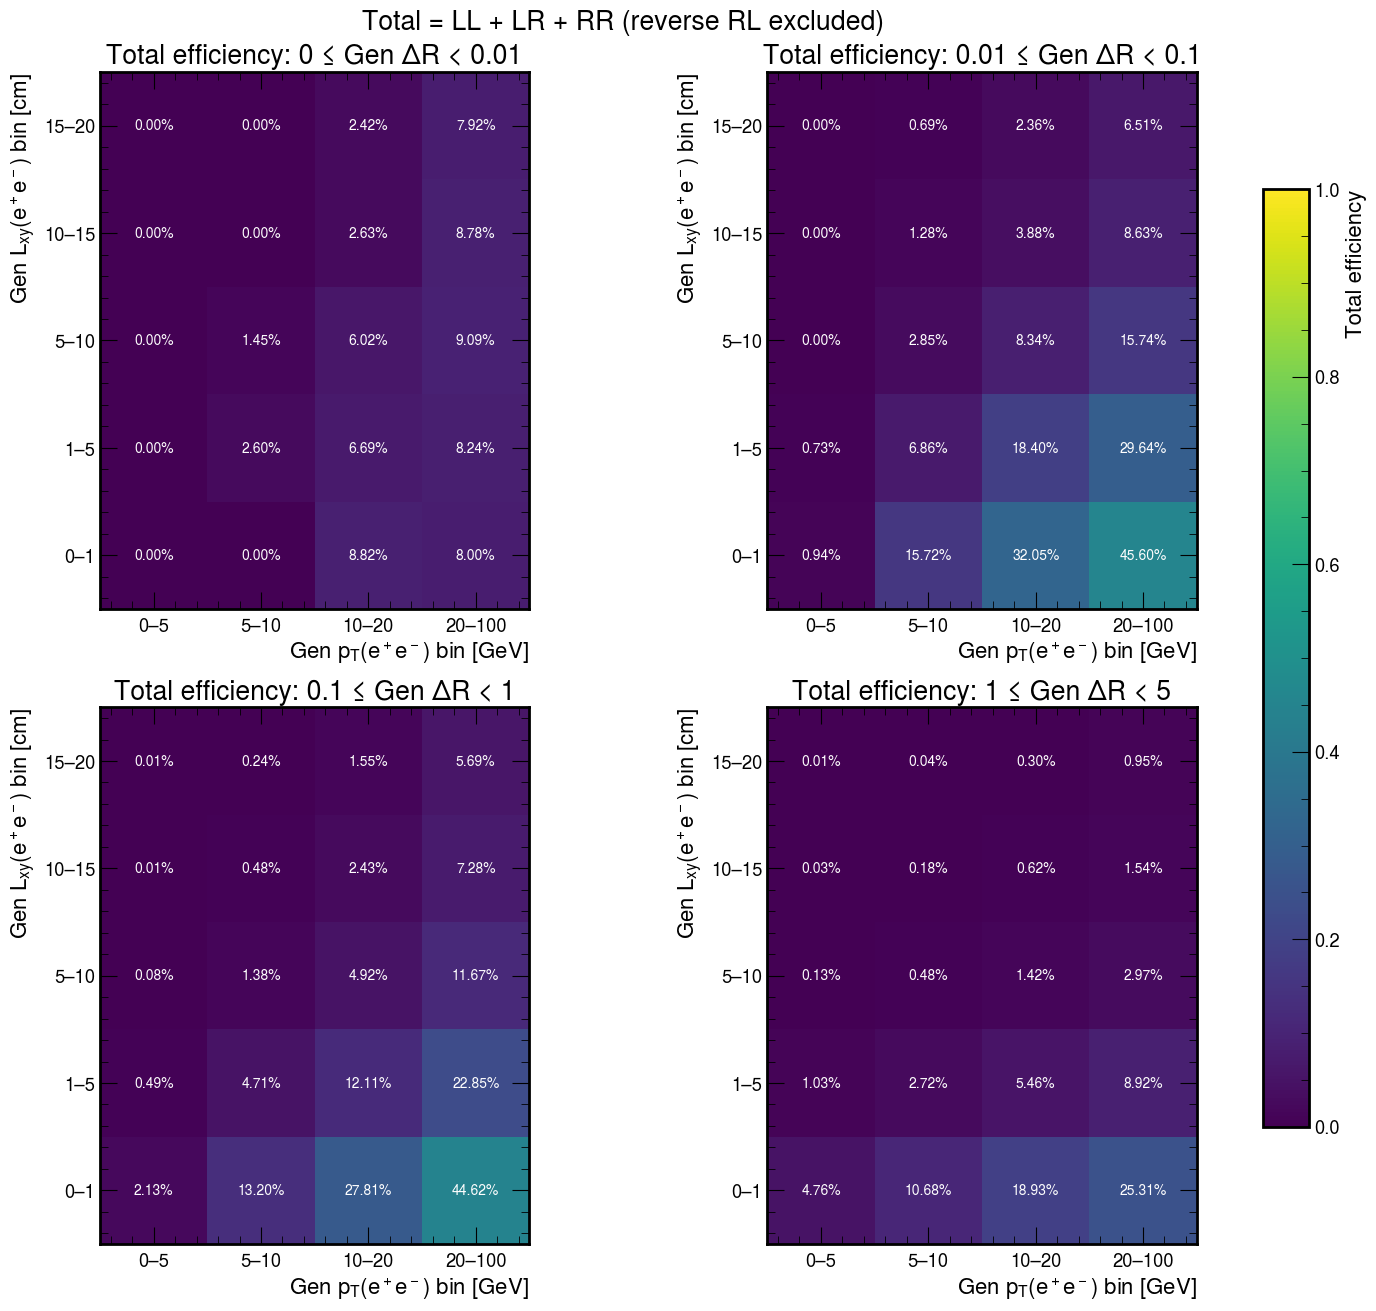

In [8]:
plot_efficiency_category('Total')


## Access individual results
For example, `results[1]['Total']['efficiency']` is the total efficiency array in ΔR bin 1. `results[1]['LL']['uncertainty'][0]` and `[1]` are its lower and upper LL uncertainty distances. Arrays are indexed as `[pT_bin, vxy_bin]`; only the display transposes them.


In [16]:
dr_bins_ordered = sorted(results)
categories = ("LL", "RR", "LR")

denominator_vs_dr = np.asarray([
    results[i]["denominator"].sum()
    for i in dr_bins_ordered
], dtype=float)

efficiencies_vs_dr = {}

print("CALCULATION SETTINGS")
print("Signal points:", samples)
print("ΔR bin order:", dr_bins_ordered)
print(f"Included pT: [{pt_edges[0]:g}, {pt_edges[-1]:g}) GeV")
print(f"Included vxy: [{vxy_edges[0]:g}, {vxy_edges[-1]:g}) cm")
print("Underflow and overflow are excluded.")
print("Method: sum numerator counts / sum denominator counts.")
print("LR includes electron-L/positron-R only.")

for category in categories:

    numerator_vs_dr = np.asarray([
        results[i][category]["numerator"].sum()
        for i in dr_bins_ordered
    ], dtype=float)

    efficiency_vs_dr, uncertainty_vs_dr = (
        efficiency_and_uncertainty(
            numerator_vs_dr,
            denominator_vs_dr,
        )
    )

    # Independently check the returned efficiency against N / D.
    direct_ratio = np.divide(
        numerator_vs_dr,
        denominator_vs_dr,
        out=np.full_like(numerator_vs_dr, np.nan),
        where=denominator_vs_dr > 0,
    )

    np.testing.assert_allclose(
        efficiency_vs_dr,
        direct_ratio,
        equal_nan=True,
    )

    summary = pd.DataFrame({
        "dr_bin": dr_bins_ordered,
        "dr_low": [
            results[i]["dr_range"][0]
            for i in dr_bins_ordered
        ],
        "dr_high": [
            results[i]["dr_range"][1]
            for i in dr_bins_ordered
        ],
        "numerator_count": numerator_vs_dr,
        "denominator_count": denominator_vs_dr,
        "efficiency": efficiency_vs_dr,
        "efficiency_percent": 100 * efficiency_vs_dr,
        "uncertainty_low": uncertainty_vs_dr[0],
        "uncertainty_high": uncertainty_vs_dr[1],
    })

    efficiencies_vs_dr[category] = {
        "numerator": numerator_vs_dr,
        "efficiency": efficiency_vs_dr,
        "uncertainty": uncertainty_vs_dr,
        "table": summary,
    }

    print(f"\n{category}: COUNTS AND CALCULATIONS")

    for position, dr_bin in enumerate(dr_bins_ordered):
        low, high = results[dr_bin]["dr_range"]
        numerator = numerator_vs_dr[position]
        denominator = denominator_vs_dr[position]

        num_shape = results[dr_bin][category]["numerator"].shape
        den_shape = results[dr_bin]["denominator"].shape

        if num_shape != den_shape:
            raise ValueError(
                f"{category}, ΔR bin {dr_bin}: "
                "numerator and denominator shapes differ."
            )

        print(
            f"Bin {dr_bin}: [{low:g}, {high:g}), "
            f"count-array shape = {num_shape}"
        )

        if denominator > 0:
            eff = efficiency_vs_dr[position]
            unc_low = uncertainty_vs_dr[0, position]
            unc_high = uncertainty_vs_dr[1, position]

            print(
                f"  {numerator:g} / {denominator:g} "
                f"= {eff:.6f} = {100 * eff:.3f}%"
            )
            print(
                f"  Uncertainty: -{unc_low:.6f}, "
                f"+{unc_high:.6f}"
            )
        else:
            print(
                f"  Numerator = {numerator:g}, denominator = 0. "
                "Efficiency undefined; no point will be plotted."
            )

    print(f"\n{category}: SUMMARY TABLE")
    print(summary.to_string(index=False))
    print("Check passed: efficiencies equal summed numerator / denominator.")

# These categories are mutually exclusive in drEff.py.
summed_category_counts = sum(
    efficiencies_vs_dr[category]["numerator"]
    for category in categories
)

if np.any(summed_category_counts > denominator_vs_dr):
    raise ValueError(
        "LL + RR + LR counts exceed the denominator. "
        "Check the histogram selections."
    )

print("\nCheck passed: LL + RR + LR counts do not exceed the denominator.")

CALCULATION SETTINGS
Cut: cut0
Signal points: {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}
ΔR bin order: [0, 1, 2, 3]
Included pT: [0, 100) GeV
Included vxy: [0, 20) cm
Underflow and overflow are excluded.
Method: sum numerator counts / sum denominator counts.
LR includes electron-L/positron-R only.

LL: COUNTS AND CALCULATIONS
Bin 0: [0, 0.01), count-array shape = (4, 5)
  135 / 2174 = 0.062098 = 6.210%
  Uncertainty: -0.005197, +0.005618
Bin 1: [0.01, 0.1), count-array shape = (4, 5)
  25460 / 209875 = 0.121310 = 12.131%
  Uncertainty: -0.000713, +0.000717
Bin 2: [0.1, 1), count-array shape = (4, 5)
  316029 / 6.58112e+06 = 0.048021 = 4.802%
  Uncertainty: -0.000083, +0.000083
Bin 3: [1, 5), count-array shape = (4, 5)
  88670 / 6.66168e+06 = 0.013310 = 1.331%
  Uncertainty: -0.000044, +0.000045

LL: SU

PLOT X-AXIS
Position 0: ΔR interval [0, 0.01)
Position 1: ΔR interval [0.01, 0.1)
Position 2: ΔR interval [0.1, 1)
Position 3: ΔR interval [1, 5)
Positions are equally spaced interval categories, not physical ΔR bin centres.

PLOTTING LL — colour: tab:blue
  ΔR [0, 0.01): y = 0.062098, error = -0.005197 / +0.005618
  ΔR [0.01, 0.1): y = 0.121310, error = -0.000713 / +0.000717
  ΔR [0.1, 1): y = 0.048021, error = -0.000083 / +0.000083
  ΔR [1, 5): y = 0.013310, error = -0.000044 / +0.000045

PLOTTING RR — colour: tab:green
  ΔR [0, 0.01): y = 0.000000, error = -0.000000 / +0.000846
  ΔR [0.01, 0.1): y = 0.006347, error = -0.000173 / +0.000178
  ΔR [0.1, 1): y = 0.026661, error = -0.000063 / +0.000063
  ΔR [1, 5): y = 0.008758, error = -0.000036 / +0.000036

PLOTTING LR — colour: tab:orange
  ΔR [0, 0.01): y = 0.000000, error = -0.000000 / +0.000846
  ΔR [0.01, 0.1): y = 0.012260, error = -0.000240 / +0.000245
  ΔR [0.1, 1): y = 0.022964, error = -0.000058 / +0.000059
  ΔR [1, 5): y = 0.

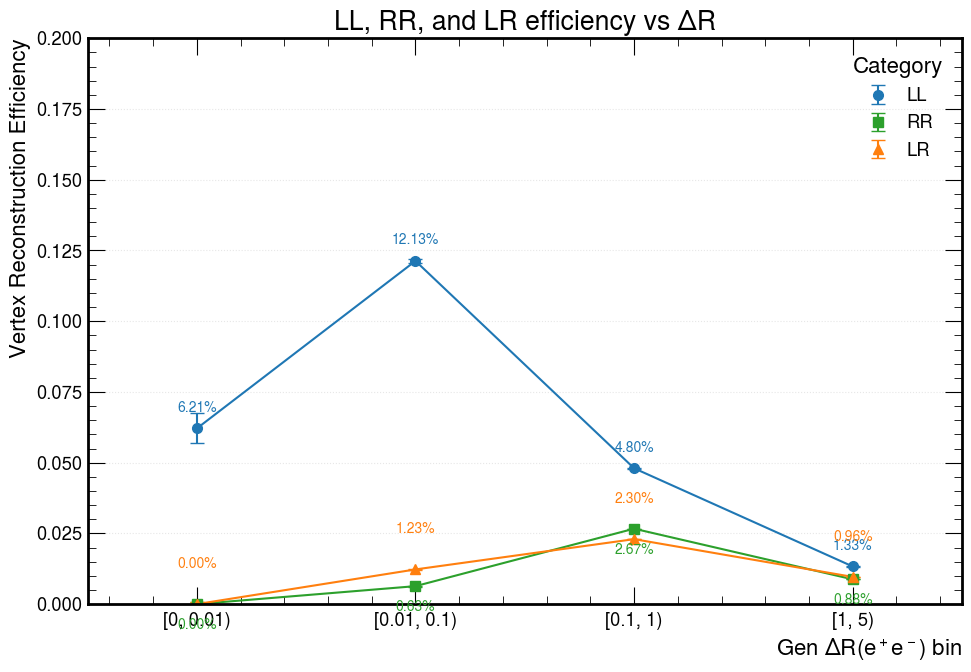

In [20]:
x_positions = np.arange(len(dr_bins_ordered))

x_labels = [
    f'[{results[i]["dr_range"][0]:g}, '
    f'{results[i]["dr_range"][1]:g})'
    for i in dr_bins_ordered
]

colours = {
    "LL": "tab:blue",
    "RR": "tab:green",
    "LR": "tab:orange",
}

markers = {
    "LL": "o",
    "RR": "s",
    "LR": "^",
}

label_offsets = {
    "LL": 12,
    "RR": -18,
    "LR": 26,
}

print("PLOT X-AXIS")
for x, label in zip(x_positions, x_labels):
    print(f"Position {x}: ΔR interval {label}")

print(
    "Positions are equally spaced interval categories, "
    "not physical ΔR bin centres."
)

fig, ax = plt.subplots(figsize=(10, 7))

for category in categories:

    efficiency = efficiencies_vs_dr[category]["efficiency"]
    uncertainty = efficiencies_vs_dr[category]["uncertainty"]
    valid = np.isfinite(efficiency)

    print(f"\nPLOTTING {category} — colour: {colours[category]}")

    for position in range(len(dr_bins_ordered)):
        if valid[position]:
            print(
                f"  ΔR {x_labels[position]}: "
                f"y = {efficiency[position]:.6f}, "
                f"error = -{uncertainty[0, position]:.6f}"
                f" / +{uncertainty[1, position]:.6f}"
            )
        else:
            print(f"  ΔR {x_labels[position]}: omitted (undefined).")

    ax.plot(
        x_positions,
        efficiency,
        color=colours[category],
        linewidth=1.5,
    )

    ax.errorbar(
        x_positions[valid],
        efficiency[valid],
        yerr=uncertainty[:, valid],
        fmt=markers[category],
        markersize=7,
        capsize=5,
        color=colours[category],
        label=category,
    )

    for x, value in zip(
        x_positions[valid], efficiency[valid]
    ):
        offset = label_offsets[category]

        if value > 0.9 and offset > 0:
            offset = -offset

        ax.annotate(
            f"{100 * value:.2f}%",
            (x, value),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            color=colours[category],
            fontsize=10,
        )

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels)
ax.set_xlim(-0.5, len(dr_bins_ordered) - 0.5)
ax.set_ylim(0, 0.2)

ax.set_xlabel(r"Gen $\Delta R(e^+e^-)$ bin")
ax.set_ylabel("Vertex Reconstruction Efficiency")
ax.set_title("LL, RR, and LR efficiency vs ΔR")

ax.grid(axis="y", alpha=0.3)
ax.legend(title="Category")

fig.tight_layout()
plt.show()

In [22]:
# SAVE ALL FIVE DISPLAYED FIGURES
# Run after the plotting cells above, using the LPC kernel.
# Heatmaps are redrawn from existing results; the analysis is not rerun.

from datetime import datetime
from pathlib import Path
from unittest.mock import patch

if "results" not in globals() or "plot_efficiency_category" not in globals():
    raise RuntimeError("Run the efficiency calculation and plotting-helper cells first.")

# The last plotting cell leaves its axis in the variable ax.
# Retain this figure before redrawing any heatmaps.
if "ax" not in globals():
    raise RuntimeError("Run the combined LL/RR/LR vs ΔR plotting cell first.")
combined_figure_to_save = ax.figure
if ax.get_title() != "LL, RR, and LR efficiency vs ΔR":
    raise RuntimeError("Run the combined LL/RR/LR vs ΔR plotting cell immediately before this cell.")

# Save on LPC, in a new directory each time, without overwriting previous files.
output_parent = LPC_REPO / "python_analysis/plots/VertexRecEff_vs_dR"
output_parent.mkdir(parents=True, exist_ok=True)
output_dir = output_parent / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
output_dir.mkdir(exist_ok=False)

saved_files = []

def save_figure(figure, name):
    for extension in ("png", "pdf"):
        destination = output_dir / f"{name}.{extension}"
        # Exclusive creation prevents overwriting an existing file.
        with destination.open("xb") as stream:
            figure.savefig(
                stream,
                format=extension,
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )
        saved_files.append(destination)
        print(f"Saved: {destination}")

# Save the existing combined plot exactly as displayed, including its y limits.
save_figure(combined_figure_to_save, "LL_RR_LR_efficiency_vs_dR")

# plt.show() may already have closed the displayed heatmaps.
# Temporarily intercept show() when redrawing each category to save its figure.
# The context manager restores the original show() even if saving fails.
for category in ("LL", "LR", "RR", "Total"):
    captured_figures = []

    def save_instead_of_show(*args, **kwargs):
        figure = plt.gcf()
        captured_figures.append(figure)
        save_figure(figure, f"{category}_efficiency_maps_all_dR_bins")

    try:
        with patch.object(plt, "show", save_instead_of_show):
            plot_efficiency_category(category)
        if len(captured_figures) != 1:
            raise RuntimeError(f"Expected one figure for {category}, got {len(captured_figures)}.")
    finally:
        for figure in captured_figures:
            plt.close(figure)

print(f"\nSaved {len(saved_files)} files: 5 PNGs and 5 PDFs.")
print(f"LPC output folder: {output_dir}")
print("Files are on LPC because this notebook uses the LPC kernel.")


Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_998675/LL_RR_LR_efficiency_vs_dR.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_998675/LL_RR_LR_efficiency_vs_dR.pdf
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_998675/LL_efficiency_maps_all_dR_bins.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_998675/LL_efficiency_maps_all_dR_bins.pdf
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_998675/LR_efficiency_maps_all_dR_bins.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_dR/20261014_161833_99